In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file == 'archive (2).zip':
            print(os.path.join(root, file))

/content/drive/MyDrive/archive (2).zip


In [4]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/archive (2).zip"
extract_path = "/content/industrial_defect_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files and folders:")
print(os.listdir(extract_path)[:20])

Dataset extracted successfully!
Files and folders:
['NEU-DET']


In [5]:
import os

dataset_path = "/content/industrial_defect_dataset/NEU-DET"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:5]:
            print("  " * (level + 1) + file)

NEU-DET/
  validation/
    annotations/
      inclusion_248.xml
      crazing_255.xml
      rolled-in_scale_272.xml
      scratches_260.xml
      patches_285.xml
    images/
  train/
    annotations/
      inclusion_156.xml
      inclusion_8.xml
      patches_105.xml
      inclusion_201.xml
      scratches_30.xml
    images/


In [6]:
import os

base = "/content/industrial_defect_dataset/NEU-DET"

for split in ["train", "validation"]:
    img_dir = os.path.join(base, split, "images")
    ann_dir = os.path.join(base, split, "annotations")

    images = os.listdir(img_dir)
    annotations = os.listdir(ann_dir)

    print(f"{split}: {len(images)} images, {len(annotations)} XML annotations")
    print("Example images:", images[:3])

train: 6 images, 1439 XML annotations
Example images: ['patches', 'crazing', 'scratches']
validation: 6 images, 361 XML annotations
Example images: ['patches', 'crazing', 'scratches']


In [7]:
import os

base = "/content/industrial_defect_dataset/NEU-DET"

for split in ["train", "validation"]:
    img_dir = os.path.join(base, split, "images")
    total = 0

    for root, dirs, files in os.walk(img_dir):
        total += sum(
            1 for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        )

    print(split, "total images:", total)
    print("Class folders:", os.listdir(img_dir))

train total images: 1440
Class folders: ['patches', 'crazing', 'scratches', 'inclusion', 'pitted_surface', 'rolled-in_scale']
validation total images: 360
Class folders: ['patches', 'crazing', 'scratches', 'inclusion', 'pitted_surface', 'rolled-in_scale']


In [8]:
!pip -q install tensorflow

import tensorflow as tf

base = "/content/industrial_defect_dataset/NEU-DET"

train_ds = tf.keras.utils.image_dataset_from_directory(
    base + "/train/images",
    image_size=(128, 128),
    batch_size=32,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base + "/validation/images",
    image_size=(128, 128),
    batch_size=32,
    label_mode="int"
)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(6, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

model.save("/content/industrial_defect_model.keras")
print("Model trained and saved!")

Found 1440 files belonging to 6 classes.
Found 360 files belonging to 6 classes.
Epoch 1/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 28s 554ms/step - accuracy: 0.1868 - loss: 1.7657 - val_accuracy: 0.2500 - val_loss: 1.7188
Epoch 2/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 590ms/step - accuracy: 0.2854 - loss: 1.6283 - val_accuracy: 0.3333 - val_loss: 1.5427
Epoch 3/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 41s 582ms/step - accuracy: 0.3938 - loss: 1.3753 - val_accuracy: 0.4944 - val_loss: 1.3543
Epoch 4/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 37s 497ms/step - accuracy: 0.6486 - loss: 1.0146 - val_accuracy: 0.5278 - val_loss: 1.1700
Epoch 5/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 42s 524ms/step - accuracy: 0.7604 - loss: 0.7559 - val_accuracy: 0.7250 - val_loss: 0.7534
Model trained and saved!


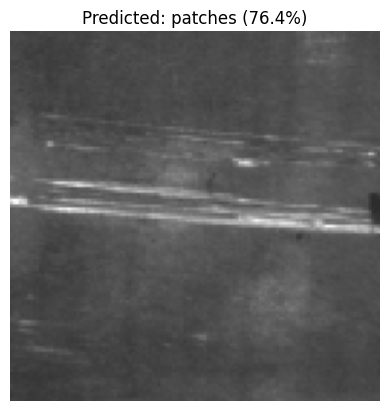

Actual class: scratches
Predicted class: patches
Confidence: 76.4%


In [9]:
import tensorflow as tf
import numpy as np
import os
import matplotlib.pyplot as plt

base = "/content/industrial_defect_dataset/NEU-DET"
model = tf.keras.models.load_model(
    "/content/industrial_defect_model.keras"
)

class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

# Select one validation image automatically
folder = os.path.join(base, "validation/images", "scratches")
image_path = next(
    os.path.join(folder, f)
    for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
)

img = tf.keras.utils.load_img(image_path, target_size=(128, 128))
arr = tf.keras.utils.img_to_array(img) / 255.0

pred = model.predict(np.expand_dims(arr, axis=0), verbose=0)[0]
idx = np.argmax(pred)

plt.imshow(img)
plt.axis("off")
plt.title(f"Predicted: {class_names[idx]} ({pred[idx]*100:.1f}%)")
plt.show()

print("Actual class: scratches")
print("Predicted class:", class_names[idx])
print(f"Confidence: {pred[idx]*100:.1f}%")

In [10]:
import shutil

source = "/content/industrial_defect_model.keras"
destination = "/content/drive/MyDrive/industrial_defect_model.keras"

shutil.copy(source, destination)

print("Model saved to Google Drive successfully!")
print(destination)

Model saved to Google Drive successfully!
/content/drive/MyDrive/industrial_defect_model.keras
